In [14]:
from __future__ import annotations

import operator
from typing import TypedDict, List, Annotated, Literal ,Optional
from langchain_groq import ChatGroq
from pathlib import Path
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

from langchain_core.messages import SystemMessage, HumanMessage
from dotenv import load_dotenv
import os
from langchain_community.tools.tavily_search import TavilySearchResults

load_dotenv(override=True)
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
print(f"API Key Loaded: {bool(os.getenv('GROQ_API_KEY'))}")
# Keep each response small enough for the Groq TPM budget.
llm = ChatGroq(model="openai/gpt-oss-120b", max_tokens=5000)

API Key Loaded: True


In [15]:
class Task(BaseModel):
    id: int
    title: str

    goal : str = Field(..., 
    description = "the sentence describing what the reader should be able to do / understand afte this section",)
    
    bullets: List[str] = Field(
        ...,
        min_length=3,
        max_length=5,
        description="3-5 bullet points to cover the topic , concrete , non-overlapping subpoints to cover in this section",
    )

    target_words : int = Field(
    ...,
    description="Target word count for this section (`120-450)",
    )

    tags: List[str] = Field(default_factory=list)
    requires_research: bool = False
    requires_citations: bool = False
    requires_code: bool = False


In [16]:
class Plan(BaseModel):
    blog_title: str
    audience: str
    tone: str
    blog_kind: Literal["explainer", "tutorial", "news_roundup", "comparison", "system_design"] = "explainer"
    constraints: List[str] = Field(default_factory=list)
    tasks: List[Task]

class EvidenceItem(BaseModel):
    title: str
    url: str
    published_at: Optional[str] = None  # keep if Tavily provides; DO NOT rely on it
    snippet: Optional[str] = None
    source: Optional[str] = None


class RouterDecision(BaseModel):
    needs_research: bool
    mode: Literal["closed_book", "hybrid", "open_book"]
    queries: List[str] = Field(default_factory=list)


class EvidencePack(BaseModel):
    evidence: List[EvidenceItem] = Field(default_factory=list)

In [17]:
class State(TypedDict):
    topic: str

    # routing / research
    mode: str
    needs_research: bool
    queries: List[str]
    evidence: List[EvidenceItem]
    plan: Optional[Plan]

    # workers
    sections: Annotated[List[tuple[int, str]], operator.add]  # (task_id, section_md)
    final: str

In [18]:
# -----------------------------
# 3) Router (decide upfront)
# -----------------------------
ROUTER_SYSTEM = """You are a routing module for a technical blog planner.

Decide whether web research is needed BEFORE planning.

Modes:
- closed_book (needs_research=false):
  Evergreen topics where correctness does not depend on recent facts (concepts, fundamentals).
- hybrid (needs_research=true):
  Mostly evergreen but needs up-to-date examples/tools/models to be useful.
- open_book (needs_research=true):
  Mostly volatile: weekly roundups, "this week", "latest", rankings, pricing, policy/regulation.

If needs_research=true:
- Output 3–10 high-signal queries.
- Queries should be scoped and specific (avoid generic queries like just "AI" or "LLM").
- If user asked for "last week/this week/latest", reflect that constraint IN THE QUERIES.
"""

def router_node(state: State) -> dict:
    
    topic = state["topic"]
    decider = llm.with_structured_output(RouterDecision)
    decision = decider.invoke(
        [
            SystemMessage(content=ROUTER_SYSTEM),
            HumanMessage(content=f"Topic: {topic}"),
        ]
    )

    return {
        "needs_research": decision.needs_research,
        "mode": decision.mode,
        "queries": decision.queries,
    }

def route_next(state: State) -> str:
    return "research" if state["needs_research"] else "orchestrator"

In [19]:
# -----------------------------
# 4) Research (Tavily)
# -----------------------------
def _tavily_search(query: str, max_results: int = 3) -> List[dict]:
    tool = TavilySearchResults(max_results=max_results)
    results = tool.invoke({"query": query})

    normalized: List[dict] = []
    for result in results or []:
        if isinstance(result, str):
            normalized.append(
                {
                    "title": "",
                    "url": result,
                    "snippet": "",
                    "published_at": None,
                    "source": None,
                }
            )
        elif isinstance(result, dict):
            normalized.append(
                {
                    "title": result.get("title") or "",
                    "url": result.get("url") or "",
                    "snippet": (result.get("content") or result.get("snippet") or "")[:300],
                    "published_at": result.get("published_date") or result.get("published_at"),
                    "source": result.get("source"),
                }
            )
    return normalized


RESEARCH_SYSTEM = """You are a research synthesizer for technical writing.

Convert raw web results into a short, deduplicated EvidencePack.
Only include non-empty URLs, prefer authoritative sources, keep snippets short,
and never guess a publication date. Deduplicate by URL."""

def research_node(state: State) -> dict:
    # Keep the evidence call small enough for the Groq TPM budget.
    queries = (state.get("queries", []) or [])[:2]
    max_results = 1
    raw_results: List[dict] = []

    for q in queries:
        raw_results.extend(_tavily_search(q, max_results=max_results))

    if not raw_results:
        return {"evidence": []}

    extractor = llm.with_structured_output(EvidencePack)
    compact_results = [
        {
            "title": result["title"],
            "url": result["url"],
            "snippet": result["snippet"],
            "published_at": result["published_at"],
        }
        for result in raw_results[:4]
    ]
    pack = extractor.invoke(
        [
            SystemMessage(content=RESEARCH_SYSTEM),
            HumanMessage(content=f"Raw results:\n{compact_results}"),
        ]
    )

    dedup = {}
    for evidence_item in pack.evidence:
        if evidence_item.url:
            dedup[evidence_item.url] = evidence_item

    return {"evidence": list(dedup.values())}

In [20]:
# -----------------------------
# 5) Orchestrator (Plan)
# -----------------------------
ORCH_SYSTEM = """You are a senior technical writer and developer advocate.
Your job is to produce a concise, actionable outline for a technical blog post.

Hard requirements:
- Create 4–6 sections (tasks) suitable for the topic and audience.
- Each task must include:
  1) goal (1 sentence)
  2) 3–4 concrete, non-overlapping bullets
  3) target word count (100–300)

Quality bar:
- Assume the reader is a developer and use correct terminology.
- Bullets must be actionable: build/compare/measure/verify/debug.
- Include at least 2 of these somewhere: a minimal code sketch, failure modes,
  performance/cost, security/privacy, or debugging/observability.

Grounding rules:
- Mode closed_book: keep it evergreen; do not depend on evidence.
- Mode hybrid: use evidence for fresh examples and mark those tasks for citations.
- Mode open_book: set blog_kind = "news_roundup" and summarize events plus implications.
  If evidence is insufficient, say so in the plan and include only supported topics.

Output must strictly match the Plan schema."""

def orchestrator_node(state: State) -> dict:
    planner = llm.with_structured_output(Plan)

    evidence = state.get("evidence", [])
    mode = state.get("mode", "closed_book")

    plan = planner.invoke(
        [
            SystemMessage(content=ORCH_SYSTEM),
            HumanMessage(
                content=(
                    f"Topic: {state['topic']}\n"
                    f"Mode: {mode}\n\n"
                    f"Evidence (ONLY use for fresh claims; may be empty):\n"
                    f"{[e.model_dump() for e in evidence][:8]}"
                )
            ),
        ]
    )

    return {"plan": plan}

In [21]:
# -----------------------------
# 6) Fanout
# -----------------------------
def fanout(state: State):
    return [
        Send(
            "worker",
            {
                "task": task.model_dump(),
                "topic": state["topic"],
                "mode": state["mode"],
                "plan": state["plan"].model_dump(),
                "evidence": [e.model_dump() for e in state.get("evidence", [])],
            },
        )
        for task in state["plan"].tasks
    ]

In [22]:
# -----------------------------
# 7) Worker (write one section)
# -----------------------------
WORKER_SYSTEM = """You are a senior technical writer and developer advocate.
Write ONE concise technical blog section in Markdown.

Hard constraints:
- Cover all bullets in order and stay close to Target words (±15%).
- Output only the section, starting with a '## <Section Title>' heading.
- If requires_citations is true, cite only provided Evidence URLs.
- If requires_code is true, include one minimal, correct code snippet.
- For open_book topics, describe events and implications, not tutorials.
- Be precise; mention important trade-offs or failure modes briefly."""


def worker_node(payload: dict) -> dict:
    task = Task(**payload["task"])
    plan = Plan(**payload["plan"])
    evidence = [EvidenceItem(**e) for e in payload.get("evidence", [])]
    topic = payload["topic"]
    mode = payload.get("mode", "closed_book")

    bullets_text = "\n- " + "\n- ".join(task.bullets)
    evidence_text = "\n".join(
        f"- {e.title} | {e.url} | {e.published_at or 'date:unknown'}".strip()
        for e in evidence[:8]
    )

    section_md = llm.invoke(
        [
            SystemMessage(content=WORKER_SYSTEM),
            HumanMessage(
                content=(
                    f"Blog: {plan.blog_title}\n"
                    f"Audience: {plan.audience}\n"
                    f"Tone: {plan.tone}\n"
                    f"Blog kind: {plan.blog_kind}\n"
                    f"Topic: {topic}\n"
                    f"Mode: {mode}\n\n"
                    f"Section title: {task.title}\n"
                    f"Goal: {task.goal}\n"
                    f"Target words: {task.target_words}\n"
                    f"Tags: {task.tags}\n"
                    f"requires_research: {task.requires_research}\n"
                    f"requires_citations: {task.requires_citations}\n"
                    f"requires_code: {task.requires_code}\n"
                    f"Bullets:{bullets_text}\n\n"
                    f"Evidence (ONLY use these URLs when citing):\n{evidence_text}\n"
                )
            ),
        ]
    ).content.strip()

    return {"sections": [(task.id, section_md)]}

In [23]:
import re

def reducer_node(state: State) -> dict:

    plan = state["plan"]

    ordered_sections = [md for _, md in sorted(state["sections"], key=lambda x: x[0])]
    body = "\n\n".join(ordered_sections).strip()
    final_md = f"# {plan.blog_title}\n\n{body}\n"

    safe_name = re.sub(r"[^a-z0-9]+", "_", plan.blog_title.lower()).strip("_") or "blog_post"
    output_path = Path.cwd() / f"{safe_name}.md"
    output_path.write_text(final_md, encoding="utf-8")
    print(f"Markdown file written to: {output_path.resolve()}")

    return {"final": final_md}

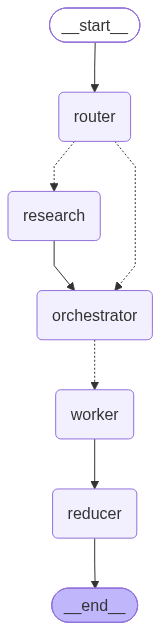

In [24]:
# -----------------------------
# 9) Build graph
# -----------------------------
g = StateGraph(State)
g.add_node("router", router_node)
g.add_node("research", research_node)
g.add_node("orchestrator", orchestrator_node)
g.add_node("worker", worker_node)
g.add_node("reducer", reducer_node)

g.add_edge(START, "router")
g.add_conditional_edges("router", route_next, {"research": "research", "orchestrator": "orchestrator"})
g.add_edge("research", "orchestrator")

g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

app = g.compile()
app

In [25]:
# -----------------------------
# 10) Runner
# -----------------------------
def run(topic: str):
    out = app.invoke(
        {
            "topic": topic,
            "mode": "",
            "needs_research": False,
            "queries": [],
            "evidence": [],
            "plan": None,
            "sections": [],
            "final": "",
        }
    )

    return out

In [ ]:
#run("Write a blog on Open Source LLMs in 2026")
run("Top news of LLM and AI models in 2026")

Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')
Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')
Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')
Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTP

Markdown file written to: E:\Projects\Project1Demo\blog-writing-agent\_bwa_practice_ipynb_codes\top_ai_and_llm_news_of_2026_releases_benchmarks_and_emerging_risks.md


{'topic': 'Top news of LLM and AI models in 2026',
 'mode': 'open_book',
 'needs_research': True,
 'queries': ['2026 major LLM releases and updates (e.g., GPT-5, Gemini 3, Claude 3)',
  '2026 AI model benchmark results and performance comparisons (e.g., MMLU, HELM)',
  '2026 AI policy and regulation changes affecting LLM deployment (e.g., EU AI Act updates)',
  '2026 AI model pricing and licensing changes for major providers (OpenAI, Anthropic, Google)',
  '2026 notable AI safety incidents or controversies involving LLMs',
  '2026 new AI hardware launches impacting LLM training (e.g., NVIDIA H100X, custom ASICs)',
  '2026 top AI research conference announcements and award-winning papers'],
 'evidence': [EvidenceItem(title='AI Updates Today (October 2026) – Latest AI Model Releases', url='https://llm-stats.com/llm-updates', published_at=None, snippet='Our open-source LLM coverage includes licensing terms, parameter count affecting inference costs, quantization support, and the community

Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')
Failed to send compressed multipart ingest: langsmith.utils.LangSmithError: Failed to POST https://api.smith.langchain.com/runs/multipart in LangSmith API. HTTPError('403 Client Error: Forbidden for url: https://api.smith.langchain.com/runs/multipart', '{"error":"Forbidden"}\n')
